#Práctica 2: Análisis Exploratorio de Datos (EDA)

##Telco Customer Churn

##Objetivo
Realizar una auditoría de calidad y un proceso de preparación del dataset Telco Customer Churn para evaluar su utilidad en la construcción de un clasificador capaz de identificar la cancelación de servicios por parte de los clientes.

El análisis comprende la comprensión del dominio, el perfilado de los datos, el análisis exploratorio, la imputación de valores ausentes, el tratamiento de valores extremos, el análisis del desbalance de clases y la evaluación de distintas estrategias de preparación y clasificación.

Se documentarán los hallazgos, las decisiones metodológicas y las limitaciones identificadas durante el proceso.

##0. Importación de bibliotecas

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SEMILLA = 42

print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


##1. Comprensión del dominio del dataset

###1.1 Carga del dataset

In [49]:
RUTA_DATASET = Path("data/telco-customer-churn.csv")

if not RUTA_DATASET.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {RUTA_DATASET.resolve()}")

df = pd.read_csv(RUTA_DATASET)
print("Dataset cargado correctamente.")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

# Inspección inicial
display(df.head())
print("\nColumnas del dataset:")
print(df.columns.tolist())
print("\nInformación general:")
df.info()

Dataset cargado correctamente.
Filas: 7043
Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Columnas del dataset:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   On

###1.2 Revisión de Church

In [50]:
TARGET = "Churn"
ID_COLUMN = "customerID"

print("Dimensiones:", df.shape)
print("\nValores de la variable objetivo:")
display(df[TARGET].value_counts(dropna=False).to_frame("Cantidad"))

print("\nIdentificadores únicos:")
print(df[ID_COLUMN].nunique())
print("\nFilas duplicadas exactas:")
print(df.duplicated().sum())
print("\nValores ausentes por columna:")
display(df.isna().sum().to_frame("Valores ausentes")
.query("`Valores ausentes` > 0"))

Dimensiones: (7043, 21)

Valores de la variable objetivo:


,Cantidad
Churn,
No,5174
Yes,1869



Identificadores únicos:
7043

Filas duplicadas exactas:
0

Valores ausentes por columna:


,Valores ausentes


###1.3 Revisión de TotalCharges

In [51]:
print("Tipo de dato original:", df["TotalCharges"].dtype)
total_charges_num = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(),
errors="coerce")

invalidos = df.loc[total_charges_num.isna(),
["customerID", "tenure", "TotalCharges", "Churn"]]

print("\nCantidad de valores no convertibles:", len(invalidos))
display(invalidos.head(10))
print("\nRepresentaciones originales encontradas:")
display(df.loc[total_charges_num.isna(), "TotalCharges"]
.value_counts(dropna=False).to_frame("Cantidad"))

Tipo de dato original: object

Cantidad de valores no convertibles: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No



Representaciones originales encontradas:


,Cantidad
TotalCharges,
,11


In [52]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip()
.replace("", np.nan), errors="coerce")

print("Tipo de dato después de la conversión:", df["TotalCharges"].dtype)
print("\nValores ausentes por columna:")
display(df.isna().sum().to_frame("Valores ausentes")
.query("`Valores ausentes` > 0"))
print("\nEstadísticas de TotalCharges:")
display(df["TotalCharges"].describe())

Tipo de dato después de la conversión: float64

Valores ausentes por columna:


,Valores ausentes
TotalCharges,11



Estadísticas de TotalCharges:


,TotalCharges
count,7032.000000
mean,2283.300441
std,2266.771362
min,18.800000
25%,401.450000
50%,1397.475000
75%,3794.737500
max,8684.800000


###1.4 Documentación del Dominio

* Fuente y licencia: Dataset Telco Customer Churn disponible públicamente en Kaggle asociado a los datos de ejemplos de IBM.

* Unidad de análisis: Cada fila representa a un cliente individual de una empresa de telecomunicaciones, con información demográfica, servicios contratados, características de su cuenta y cargos.

* Atributos principales

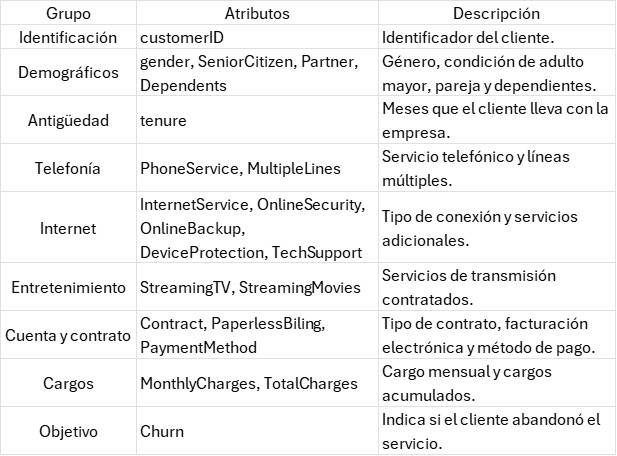

* Variable objetivo: Churn, que indica si un cliente canceló el servicio.

Preguntas clave del dominio:
1. **¿Qué representa cada fila?**
Cada fila representa a un cliente de una empresa de telecomunicaciones e incluye información demográfica, servicios contratados, antigüedad, características de la cuenta y cargos.

2. **¿La variable objetivo estaría disponible en un escenario real?**
`Churn` estaría disponible después de registrar si un cliente canceló el servicio. Para predecir cancelaciones futuras, se utiliza como etiqueta durante el entrenamiento y la evaluación, pero no como variable predictora.

3. **¿Existen identificadores o variables con fuga de información?**
`customerID` identifica de forma única a cada cliente y debe excluirse de los predictores. También es necesario verificar que las variables utilizadas, como `TotalCharges` y `tenure`, correspondan al momento de la predicción. No se ha confirmado una fuga de información, pero debe prevenirse el uso de datos que solo estarían disponibles después de la cancelación.

4. **¿Qué decisiones podrían afectar de forma desigual a distintos grupos?**
El uso de las predicciones para seleccionar clientes para campañas de retención o beneficios podría afectar de forma desigual a grupos definidos por variables como `gender`, `SeniorCitizen` o `Dependents`. Se deberán comparar las métricas de evaluación entre grupos para identificar posibles diferencias en los errores del clasificador.

##2. Data Profiling

###2.1 Tipos de datos, valores ausentes y valores únicos

In [53]:
perfil_general = pd.DataFrame({"Tipo de dato": df.dtypes.astype(str),
"Valores válidos": df.notna().sum(), "Valores ausentes": df.isna().sum(),
"% ausentes": (df.isna().mean() * 100).round(2), "Valores únicos": df.nunique(dropna=True)})
display(perfil_general)


,Tipo de dato,Valores válidos,Valores ausentes,% ausentes,Valores únicos
customerID,object,7043,0,0.00,7043
gender,object,7043,0,0.00,2
SeniorCitizen,int64,7043,0,0.00,2
Partner,object,7043,0,0.00,2
Dependents,object,7043,0,0.00,2
tenure,int64,7043,0,0.00,73
PhoneService,object,7043,0,0.00,2
MultipleLines,object,7043,0,0.00,3
InternetService,object,7043,0,0.00,3
OnlineSecurity,object,7043,0,0.00,3


###2.2 Estadísticas descriptivas de las variables numéricas

In [54]:
columnas_numericas = df.select_dtypes(include="number").columns.tolist()
perfil_numerico = df[columnas_numericas].describe().T
perfil_numerico["mediana"] = df[columnas_numericas].median()
perfil_numerico["asimetria"] = df[columnas_numericas].skew()
display(perfil_numerico.round(3))

,count,mean,std,min,25%,50%,75%,max,mediana,asimetria
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00,0.000,1.834
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00,29.000,0.240
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75,70.350,-0.221
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80,1397.475,0.962


###2.3 Estadísticas de las variables categóricas

In [55]:
columnas_categoricas = df.select_dtypes(include=["object", "category"]
).columns.tolist()

perfil_categorico = pd.DataFrame({"Valores únicos": df[columnas_categoricas]
.nunique(dropna=True), "Moda": df[columnas_categoricas].mode().iloc[0],
"Frecuencia de la moda": [df[col].value_counts(dropna=False).iloc[0]
for col in columnas_categoricas],
  "Valores ausentes": df[columnas_categoricas].isna().sum()})

display(perfil_categorico)


,Valores únicos,Moda,Frecuencia de la moda,Valores ausentes
customerID,7043,0002-ORFBO,1,0
gender,2,Male,3555,0
Partner,2,No,3641,0
Dependents,2,No,4933,0
PhoneService,2,Yes,6361,0
MultipleLines,3,No,3390,0
InternetService,3,Fiber optic,3096,0
OnlineSecurity,3,No,3498,0
OnlineBackup,3,No,3088,0
DeviceProtection,3,No,3095,0


###2.4 Revisar dominios y valores potencialmente inválidos

In [56]:
dominios_esperados = {"gender": {"Female", "Male"}, "SeniorCitizen": {0, 1},
"Partner": {"Yes", "No"}, "Dependents": {"Yes", "No"}, "PhoneService": {"Yes", "No"},
"MultipleLines": {"Yes", "No", "No phone service"}, "InternetService": {"DSL", "Fiber optic", "No"},
"OnlineSecurity": {"Yes", "No", "No internet service"}, "OnlineBackup": {"Yes", "No", "No internet service"},
"DeviceProtection": {"Yes", "No", "No internet service"}, "TechSupport": {"Yes", "No", "No internet service"},
"StreamingTV": {"Yes", "No", "No internet service"}, "StreamingMovies": {"Yes", "No", "No internet service"},
"Contract": {"Month-to-month", "One year", "Two year"}, "PaperlessBilling": {"Yes", "No"},
"PaymentMethod": {"Electronic check", "Mailed check", "Bank transfer (automatic)",
"Credit card (automatic)"}, "Churn": {"Yes", "No"}}
hallazgos_dominio = []

for columna, valores_esperados in dominios_esperados.items():
    valores_observados = set(df[columna].dropna().unique())
    invalidos = valores_observados - valores_esperados

    hallazgos_dominio.append({"Columna": columna,
    "Valores distintos": len(valores_observados),
    "Valores potencialmente inválidos": sorted(invalidos, key=str)})

display(pd.DataFrame(hallazgos_dominio))

,Columna,Valores distintos,Valores potencialmente inválidos
0,gender,2,[]
1,SeniorCitizen,2,[]
2,Partner,2,[]
3,Dependents,2,[]
4,PhoneService,2,[]
5,MultipleLines,3,[]
6,InternetService,3,[]
7,OnlineSecurity,3,[]
8,OnlineBackup,3,[]
9,DeviceProtection,3,[]


###2.5 Detectar columnas constantes o casi constantes

In [57]:
resumen_frecuencias = []

for columna in df.columns:
    frecuencias = df[columna].value_counts(normalize=True, dropna=False)
    proporcion_maxima = (frecuencias.iloc[0] if not frecuencias.empty else np.nan)

    resumen_frecuencias.append({"Columna": columna,
    "Valores únicos": df[columna].nunique(dropna=True),
    "Valor más frecuente": (frecuencias.index[0] if not frecuencias.empty else None),
    "Frecuencia máxima (%)": (proporcion_maxima * 100
      if pd.notna(proporcion_maxima) else np.nan),
        "Clasificación preliminar": (
        "Constante" if df[columna].nunique(dropna=False) == 1
      else "Casi constante" if proporcion_maxima >= 0.95
      else "Sin alerta")})

perfil_frecuencias = pd.DataFrame(resumen_frecuencias)

display(perfil_frecuencias.sort_values("Frecuencia máxima (%)",
ascending=False).round(2))

,Columna,Valores únicos,Valor más frecuente,Frecuencia máxima (%),Clasificación preliminar
6,PhoneService,2,Yes,90.32,Sin alerta
2,SeniorCitizen,2,0,83.79,Sin alerta
20,Churn,2,No,73.46,Sin alerta
4,Dependents,2,No,70.04,Sin alerta
16,PaperlessBilling,2,Yes,59.22,Sin alerta
15,Contract,3,Month-to-month,55.02,Sin alerta
3,Partner,2,No,51.70,Sin alerta
1,gender,2,Male,50.48,Sin alerta
9,OnlineSecurity,3,No,49.67,Sin alerta
12,TechSupport,3,No,49.31,Sin alerta


###2.6 Revisión de categorías inconsistentes

In [58]:
columnas_texto = df.select_dtypes(include=["object", "category"]).columns
revision_categorias = []

for columna in columnas_texto:
    valores = df[columna].dropna().astype(str)
    espacios = valores[valores != valores.str.strip()]
    diferencias_mayusculas = (valores.str.lower().nunique() < valores.nunique())
    cadenas_vacias = valores[valores.str.strip() == ""]

    revision_categorias.append({"Columna": columna,
    "Valores con espacios externos": len(espacios),
    "Posibles diferencias de mayúsculas": diferencias_mayusculas,
    "Cadenas vacías": len(cadenas_vacias)})

perfil_inconsistencias = pd.DataFrame(revision_categorias)
display(perfil_inconsistencias)

,Columna,Valores con espacios externos,Posibles diferencias de mayúsculas,Cadenas vacías
0,customerID,0,False,0
1,gender,0,False,0
2,Partner,0,False,0
3,Dependents,0,False,0
4,PhoneService,0,False,0
5,MultipleLines,0,False,0
6,InternetService,0,False,0
7,OnlineSecurity,0,False,0
8,OnlineBackup,0,False,0
9,DeviceProtection,0,False,0


###2.8 Matriz de correlación



,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.102
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.102,0.826,0.651,1.000


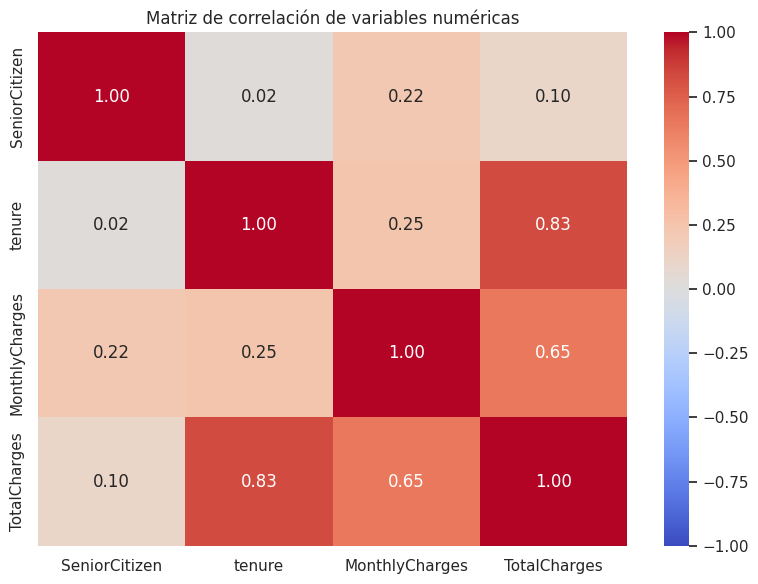

In [59]:
columnas_numericas = df.select_dtypes(include="number").columns.tolist()
matriz_correlacion = df[columnas_numericas].corr(method="pearson")
display(matriz_correlacion.round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap="coolwarm", fmt=".2f",
vmin=-1, vmax=1, center=0)
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

In [60]:
correlaciones_pares = (matriz_correlacion
.where(np.triu(np.ones(matriz_correlacion.shape), k=1).astype(bool))
.stack().reset_index())

correlaciones_pares.columns = ["Variable 1", "Variable 2", "Correlación"]
correlaciones_pares["Correlación absoluta"] = (
correlaciones_pares["Correlación"].abs())
correlaciones_altas = (correlaciones_pares[
correlaciones_pares["Correlación absoluta"] >= 0.70]
.sort_values("Correlación absoluta", ascending=False).reset_index(drop=True))

display(correlaciones_altas.round(3))

,Variable 1,Variable 2,Correlación,Correlación absoluta
0,tenure,TotalCharges,0.826,0.826


### 2.8 Revisión de posibles fugas de información

In [61]:
revision_fuga = pd.DataFrame([
{"Variable": "customerID",
"Pregunta de revisión": "¿Es una característica del cliente o solo un identificador?",
"Disponibilidad temporal": "Disponible, pero identifica al cliente",
"Acción preliminar": "Excluir de los predictores"},
{"Variable": "Churn",
"Pregunta de revisión": "¿Se conoce antes de predecir una cancelación futura?",
"Disponibilidad temporal": "Es la variable objetivo",
"Acción preliminar": "Usar como etiqueta, no como predictor"},
{"Variable": "tenure",
"Pregunta de revisión": "¿La antigüedad se calcula hasta la fecha de predicción?",
"Disponibilidad temporal": "Depende de la fecha de corte",
"Acción preliminar": "Verificar la fecha de referencia"},
{"Variable": "MonthlyCharges",
"Pregunta de revisión": "¿El cargo mensual corresponde a la información disponible en la fecha de predicción?",
"Disponibilidad temporal": "Depende de la fecha de corte",
"Acción preliminar": "Verificar la fecha de referencia"},
{"Variable": "TotalCharges",
"Pregunta de revisión": "¿Los cargos acumulados corresponden únicamente al periodo previo a la predicción?",
"Disponibilidad temporal": "Depende de la fecha de corte",
"Acción preliminar": "Verificar la fecha de referencia"}])

display(revision_fuga)

,Variable,Pregunta de revisión,Disponibilidad temporal,Acción preliminar
0,customerID,¿Es una característica del cliente o solo un i...,"Disponible, pero identifica al cliente",Excluir de los predictores
1,Churn,¿Se conoce antes de predecir una cancelación f...,Es la variable objetivo,"Usar como etiqueta, no como predictor"
2,tenure,¿La antigüedad se calcula hasta la fecha de pr...,Depende de la fecha de corte,Verificar la fecha de referencia
3,MonthlyCharges,¿El cargo mensual corresponde a la información...,Depende de la fecha de corte,Verificar la fecha de referencia
4,TotalCharges,¿Los cargos acumulados corresponden únicamente...,Depende de la fecha de corte,Verificar la fecha de referencia


###2.9 Hallazgos importantes

- Estructura y calidad de los datos: el dataset contiene 7,043 registros y 21 columnas. Inicialmente, TotalCharges se encontraba como texto, por lo que se convirtió a tipo numérico. Durante la conversión se identificaron 11 valores vacíos, equivalentes al 0.16 % de los registros, que se conservaron como valores ausentes para su tratamiento posterior.
- Distribución de la variable objetivo: la variable Churn presenta un desbalance entre sus clases: el 73.45 % de los clientes no canceló el servicio y el 26.55 % sí lo hizo. Esta diferencia deberá considerarse al evaluar los modelos de clasificación.
- Integridad y consistencia: no se encontraron filas duplicadas exactas ni valores fuera de los dominios definidos. Tampoco se detectaron espacios externos, diferencias de mayúsculas o cadenas vacías en las columnas categóricas revisadas.
- Columnas constantes e identificadores: no se identificaron columnas constantes o casi constantes con el umbral del 95 % establecido. La columna customerID contiene un identificador único por registro, por lo que no debe utilizarse directamente como predictor del modelo.
- Correlaciones elevadas: se encontró una correlación positiva de 0.826 entre tenure y TotalCharges. Esta relación puede indicar redundancia parcial entre ambas variables, por lo que conviene considerar su comportamiento durante la preparación y evaluación del modelo.
- Posibles fugas de información: no se confirmó una fuga de información. Sin embargo, es necesario verificar que tenure, MonthlyCharges y TotalCharges representen información disponible antes del momento en que se pretende predecir la cancelación. Además, Churn debe utilizarse como variable objetivo y no como predictor.

##3. Análisis Exploratorio

###3.1 Distribución de variables numéricas

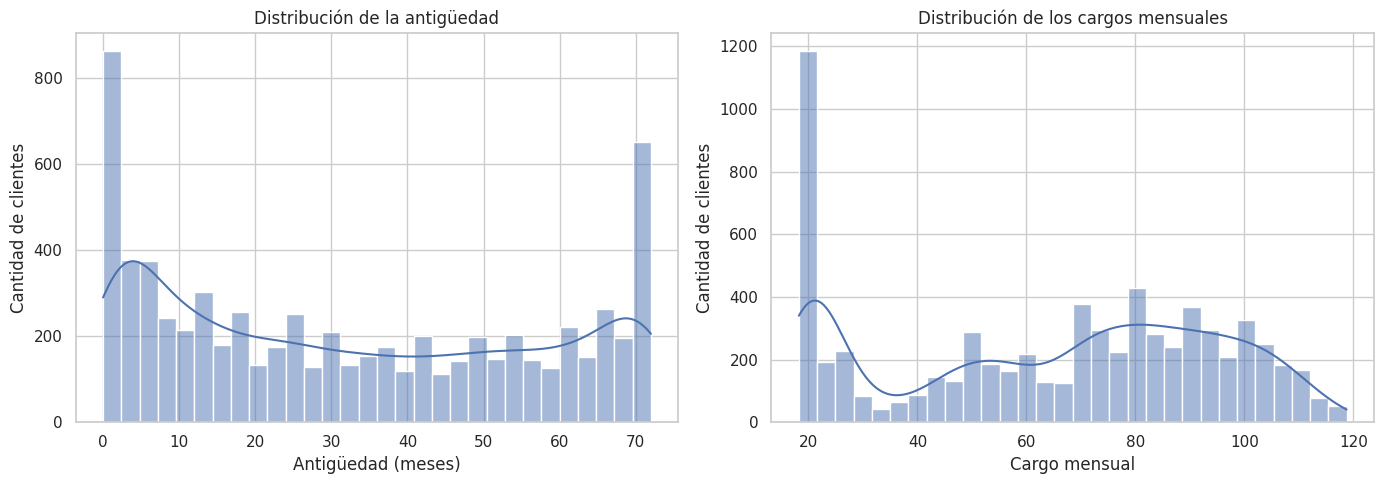

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="tenure", kde=True,
bins=30, ax=axes[0])
axes[0].set_title("Distribución de la antigüedad")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("Cantidad de clientes")

sns.histplot(data=df, x="MonthlyCharges", kde=True,
bins=30, ax=axes[1])
axes[1].set_title("Distribución de los cargos mensuales")
axes[1].set_xlabel("Cargo mensual")
axes[1].set_ylabel("Cantidad de clientes")

plt.tight_layout()
plt.show()

- Distribución de la antigüedad (gráfico izquierdo): Mide la cantidad de clientes en función de su antigüedad en meses (eje horizontal, de 0 a más de 70 meses). Se observa un pico muy alto de clientes nuevos (cerca de 0 a 2 meses) y otro pico significativo de clientes con alta fidelidad o antigüedad máxima (alrededor de 70 a 72 meses), mientras que el resto de los valores se distribuyen de manera más uniforme entre los 5 y los 65 meses.
- Distribución de los cargos mensuales (gráfico derecho): Mide la cantidad de clientes según el monto de su cargo mensual (eje horizontal, aproximadamente de 20 a 120). Destaca un pico muy elevado de clientes concentrados en el rango de menor costo (cerca de 20), y una distribución bimodal o multinodal a lo largo de los valores intermedios y altos (con mayor concentración entre los 70 y 100).

###3.2 Diagramas de caja (boxplots)

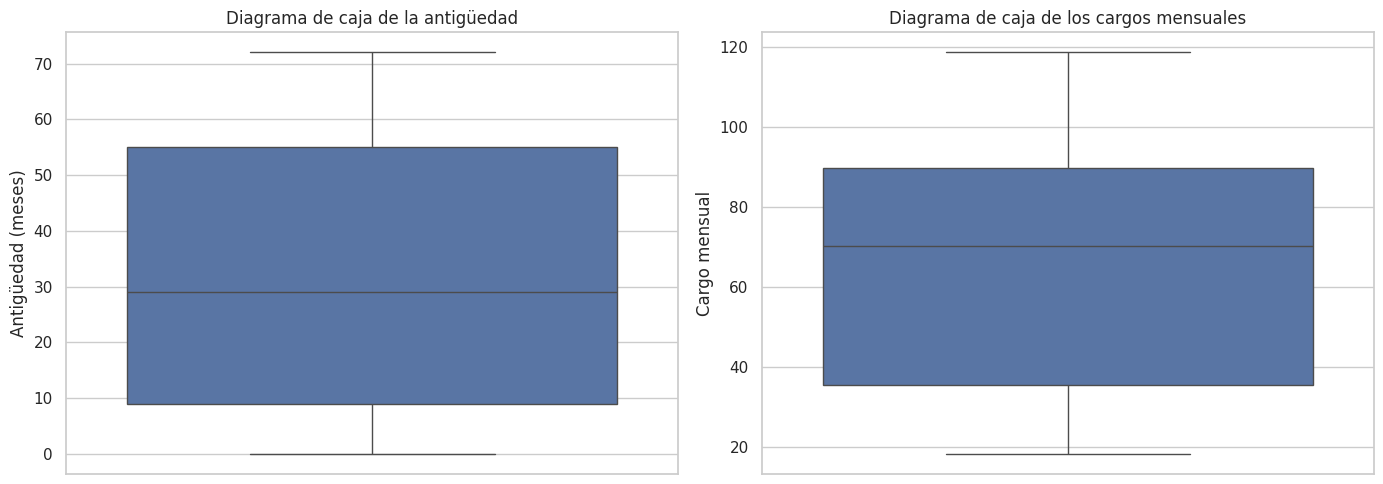

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y="tenure", ax=axes[0])
axes[0].set_title("Diagrama de caja de la antigüedad")
axes[0].set_ylabel("Antigüedad (meses)")
sns.boxplot(data=df, y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Diagrama de caja de los cargos mensuales")
axes[1].set_ylabel("Cargo mensual")
plt.tight_layout()
plt.show()

1. Diagrama de caja de la antigüedad (gráfico izquierdo):
La mediana (la línea central dentro de la caja) se sitúa aproximadamente en los 29 meses.
El rango intercuartílico (IQR), representado por la caja azul, abarca desde el primer cuartil (aproximadamente 9 meses) hasta el tercer cuartil (alrededor de 55 meses).
Los bigotes se extienden desde el valor mínimo de 0 meses hasta el valor máximo de aproximadamente 72 meses, lo que indica que no hay valores atípicos (outliers) aparentes fuera de estos límites en esta variable.

2. Diagrama de caja de los cargos mensuales (gráfico derecho):
La mediana de los cargos mensuales se encuentra cerca de los 70.
La caja muestra que el 50% central de los datos se distribuye entre un primer cuartil de aproximadamente 35 y un tercer cuartil cercano a los 90.
Los bigotes cubren desde el valor mínimo (alrededor de 18 o 20) hasta el valor máximo (cerca de 120), mostrando también una distribución completa sin valores atípicos marcados fuera de los rangos descritos.

###3.3 Análisis de variables categóricas

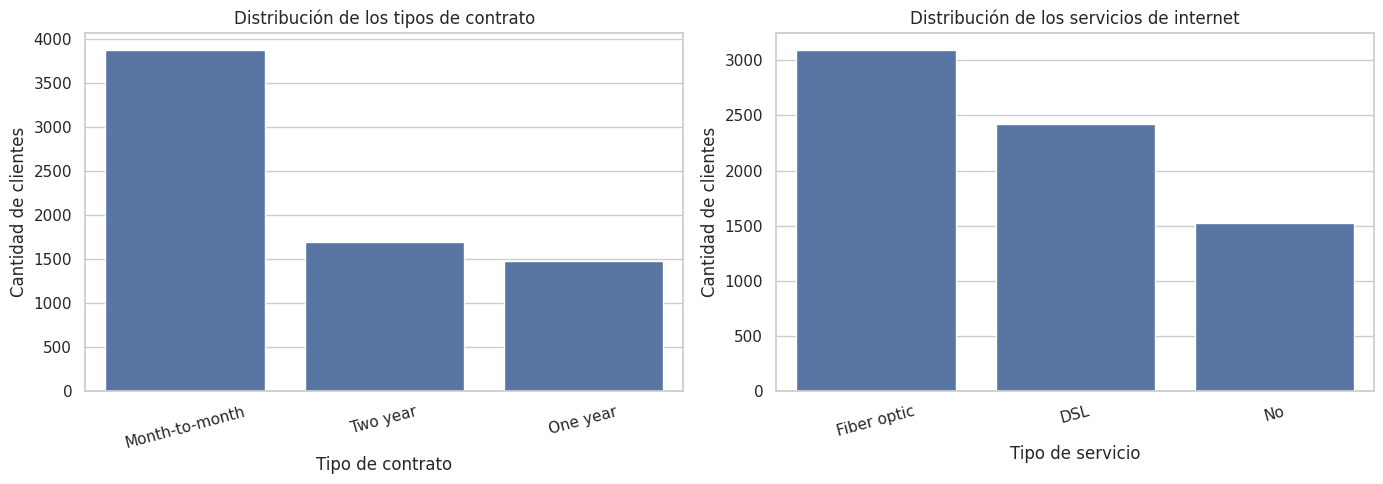

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="Contract",
order=df["Contract"].value_counts().index, ax=axes[0])
axes[0].set_title("Distribución de los tipos de contrato")
axes[0].set_xlabel("Tipo de contrato")
axes[0].set_ylabel("Cantidad de clientes")
axes[0].tick_params(axis="x", rotation=15)
sns.countplot(data=df, x="InternetService",
order=df["InternetService"].value_counts().index, ax=axes[1])
axes[1].set_title("Distribución de los servicios de internet")
axes[1].set_xlabel("Tipo de servicio")
axes[1].set_ylabel("Cantidad de clientes")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

1. Distribución de los tipos de contrato (gráfico izquierdo):
Representa la cantidad de clientes según la modalidad de su contrato.
El contrato Month-to-month (mes a mes) es por mucho el más popular, superando los 3,800 clientes.   Le siguen los contratos de dos años (Two year) con cerca de 1,700 clientes y los de un año (One year) con aproximadamente 1,500 clientes.
2. Distribución de los servicios de internet (gráfico derecho):
Muestra la cantidad de clientes según el tipo de servicio de internet contratado.
La opción de Fiber optic (fibra óptica) encabeza la lista con más de 3,000 clientes.
El servicio DSL se ubica en segundo lugar con cerca de 2,400 clientes.
Por último, los clientes que no cuentan con servicio de internet (No) suman alrededor de 1,500.

###3.4 Distribución de la variable objetivo: Churn

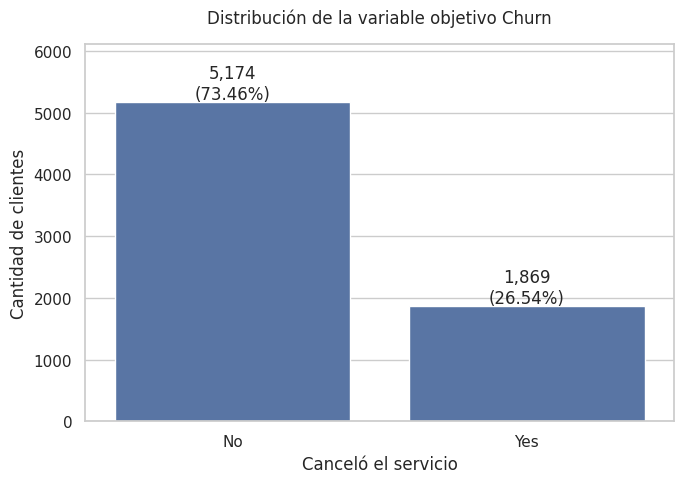

In [65]:
orden_churn = ["No", "Yes"]
conteo_churn = df["Churn"].value_counts().reindex(orden_churn)
porcentaje_churn = df["Churn"].value_counts(normalize=True).reindex(orden_churn) * 100
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="Churn", order=orden_churn)

for i, categoria in enumerate(orden_churn):
    cantidad = conteo_churn[categoria]
    porcentaje = porcentaje_churn[categoria]
    ax.text(i, cantidad + 50, f"{cantidad:,}\n({porcentaje:.2f}%)", ha="center")

plt.title("Distribución de la variable objetivo Churn")
plt.xlabel("Canceló el servicio")
plt.ylabel("Cantidad de clientes")
ax.set_ylim(0, conteo_churn.max() * 1.18)
ax.set_title("Distribución de la variable objetivo Churn", pad=15)
plt.tight_layout()
plt.show()

La gráfica muestra que 5,174 clientes no cancelaron el servicio (No), lo que representa el 73.46 % de los registros, mientras que 1,869 clientes sí lo cancelaron (Yes), equivalentes al 26.54 %.

Esta distribución evidencia un desbalance de clases, ya que la categoría No contiene una proporción considerablemente mayor de registros que la categoría Yes. Esta diferencia deberá considerarse al evaluar el desempeño del clasificador, para evitar que la exactitud general o accuracy oculte dificultades para identificar a los clientes que cancelan el servicio.

###3.5 Análisis bivariado: tipo de contrato frente a Churn

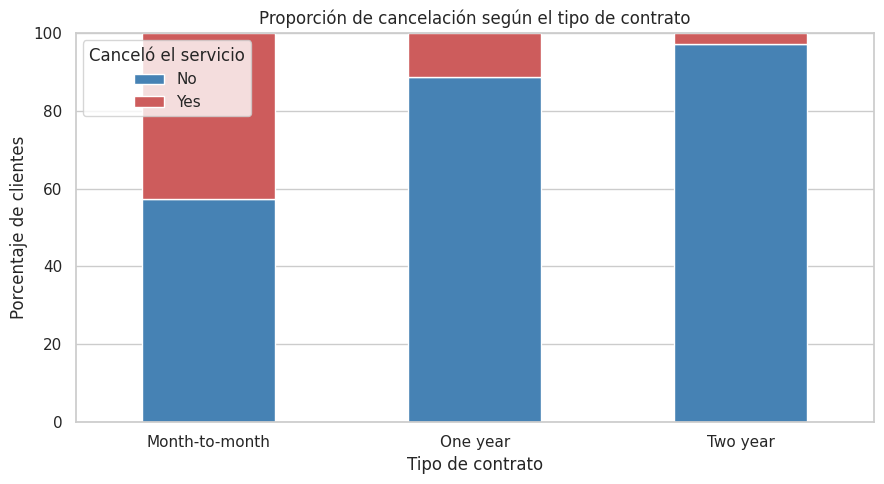

In [66]:
proporcion_churn = pd.crosstab(df["Contract"], df["Churn"],
normalize="index") * 100
proporcion_churn = proporcion_churn.reindex(columns=["No", "Yes"])
ax = proporcion_churn.plot(kind="bar", stacked=True,
figsize=(9, 5), color=["steelblue", "indianred"])
ax.set_title("Proporción de cancelación según el tipo de contrato")
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Porcentaje de clientes")
ax.set_ylim(0, 100)
ax.legend(title="Canceló el servicio", labels=["No", "Yes"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

La gráfica muestra una relación entre el tipo de contrato y la cancelación del servicio. Los clientes con contratos mensuales (Month-to-month) presentan la mayor proporción de cancelaciones, aproximadamente del 40 %. En los contratos de un año (One year), la proporción disminuye considerablemente, ya que cerca del 90 % de los clientes mantienen el servicio. Finalmente, los contratos de dos años (Two year) presentan la menor proporción de cancelaciones, con alrededor del 3 % al 5 %.

Estos resultados muestran que las cancelaciones son más frecuentes entre los clientes con contratos mensuales, mientras que los contratos de mayor duración se asocian con una mayor permanencia. Sin embargo, esta gráfica muestra una asociación y no demuestra que la duración del contrato sea la causa directa de la cancelación.

###3.6 Matriz de correlación

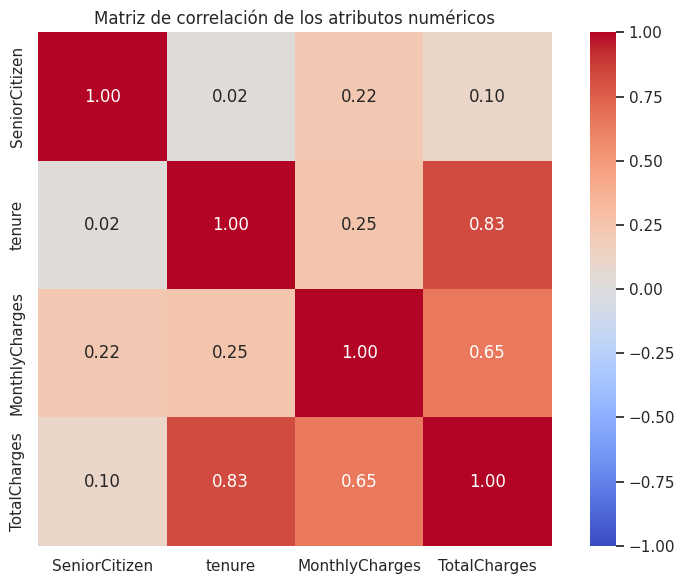

In [67]:
variables_numericas = ["SeniorCitizen", "tenure",
"MonthlyCharges", "TotalCharges"]
matriz_correlacion = df[variables_numericas].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap="coolwarm",
vmin=-1, vmax=1, center=0, fmt=".2f", square=True)
plt.title("Matriz de correlación de los atributos numéricos")
plt.tight_layout()
plt.show()

La matriz muestra una correlación positiva alta entre la antigüedad (tenure) y los cargos totales (TotalCharges), con un valor de 0.83. Esto indica que los clientes que llevan más tiempo con el servicio tienden a acumular mayores cargos. También se observa una correlación positiva entre los cargos mensuales (MonthlyCharges) y los cargos totales (TotalCharges), con un valor de 0.65, así como una correlación débil entre la antigüedad y los cargos mensuales (0.25).

Por otro lado, SeniorCitizen presenta correlaciones débiles con las demás variables, con valores entre 0.02 y 0.22. En general, la relación más destacada se encuentra entre la antigüedad y los cargos totales. Estas correlaciones describen relaciones lineales entre las variables, pero no implican causalidad.

##4. Imputación de valores perdidos

###4.1 Preparar los datos para comparar las estrategias

In [68]:
df_imputacion = df.copy()
df_imputacion["TotalCharges_missing"] = (df_imputacion["TotalCharges"].isnull().astype(int))
variable_categorica = "InternetService"
rng = np.random.default_rng(SEMILLA)
indices_categoricos = df_imputacion.sample(frac=0.05, random_state=SEMILLA).index
df_imputacion.loc[indices_categoricos, variable_categorica] = np.nan

print("Valores ausentes en TotalCharges:", df_imputacion["TotalCharges"].isnull().sum())
print("Valores ausentes simulados en InternetService:", df_imputacion["InternetService"].isnull().sum())

Valores ausentes en TotalCharges: 11
Valores ausentes simulados en InternetService: 352


###4.2 Aplicar las estrategias A y B

Estrategia A: Media y Moda

Estrategia B: Mediana y Categoria: Desconocido

In [69]:
df_A = df_imputacion.copy()
df_B = df_imputacion.copy()

# Estrategia A: media y moda
media_total = df_A["TotalCharges"].mean()
moda_internet = df_A["InternetService"].mode()[0]
df_A["TotalCharges"] = df_A["TotalCharges"].fillna(media_total)
df_A["InternetService"] = df_A["InternetService"].fillna(moda_internet)

# Estrategia B: mediana y categoría Desconocido
mediana_total = df_B["TotalCharges"].median()
df_B["TotalCharges"] = df_B["TotalCharges"].fillna(mediana_total)
df_B["InternetService"] = df_B["InternetService"].fillna("Desconocido")

comparacion_ausentes = pd.DataFrame({"Conjunto": ["Original de trabajo",
"Estrategia A", "Estrategia B"], "Ausentes en TotalCharges": [
df_imputacion["TotalCharges"].isnull().sum(), df_A["TotalCharges"].isnull().sum(),
df_B["TotalCharges"].isnull().sum()], "Ausentes en InternetService": [
df_imputacion["InternetService"].isnull().sum(), df_A["InternetService"].isnull().sum(),
df_B["InternetService"].isnull().sum()]})

display(comparacion_ausentes)
print(f"Media de TotalCharges: {media_total:.2f}")
print(f"Mediana de TotalCharges: {mediana_total:.2f}")
print(f"Moda de InternetService: {moda_internet}")

,Conjunto,Ausentes en TotalCharges,Ausentes en InternetService
0,Original de trabajo,11,352
1,Estrategia A,0,0
2,Estrategia B,0,0


Media de TotalCharges: 2283.30
Mediana de TotalCharges: 1397.47
Moda de InternetService: Fiber optic


###4.3 Comparar los cambios en la distribución y la varianza

In [70]:
estadisticas = {}
for nombre, datos in [
    ("Original (sin ausentes)", df_imputacion["TotalCharges"]),
    ("Estrategia A: media", df_A["TotalCharges"]),
    ("Estrategia B: mediana", df_B["TotalCharges"])]:
    estadisticas[nombre] = {"Media": datos.mean(),
    "Mediana": datos.median(), "Desviación estándar": datos.std(),
    "Varianza": datos.var(), "Mínimo": datos.min(), "Máximo": datos.max()}

comparacion_estadisticas = pd.DataFrame(estadisticas).T
display(comparacion_estadisticas.round(2))

,Media,Mediana,Desviación estándar,Varianza,Mínimo,Máximo
Original (sin ausentes),2283.30,1397.48,2266.77,5138252.41,18.8,8684.8
Estrategia A: media,2283.30,1400.55,2265.00,5130226.17,18.8,8684.8
Estrategia B: mediana,2281.92,1397.48,2265.27,5131449.98,18.8,8684.8


Los resultados muestran que ambas estrategias producen cambios pequeños en las estadísticas de TotalCharges. La imputación por media conserva la media en 2283.30 y modifica ligeramente la mediana, que pasa de 1397.48 a 1400.55. Por su parte, la imputación por mediana mantiene la mediana en 1397.48, mientras que la media disminuye ligeramente a 2281.92.

La desviación estándar y la varianza disminuyen ligeramente con ambas estrategias, lo que indica una pequeña reducción en la dispersión de los datos. Los valores mínimo y máximo permanecen iguales. En este caso, la diferencia entre los métodos es reducida, aunque la media y la mediana no representan los datos de la misma manera: la mediana es menos sensible a valores extremos.

###4.4 Comparar las variables categóricas

In [71]:
frecuencias_originales = df["InternetService"].value_counts()
comparacion_categorica = pd.DataFrame({"Original": frecuencias_originales,
"Estrategia A (moda)": df_A["InternetService"].value_counts(),
"Estrategia B (Desconocido)": df_B["InternetService"].value_counts()
}).fillna(0).astype(int)
display(comparacion_categorica)

,Original,Estrategia A (moda),Estrategia B (Desconocido)
InternetService,,,
DSL,2421,2310,2310
Desconocido,0,0,352
Fiber optic,3096,3290,2938
No,1526,1443,1443


La imputación por moda (estrategia A) reemplaza los 352 valores ausentes simulados por la categoría más frecuente, Fiber optic. Como resultado, esta categoría aumenta de 3096 a 3290 registros, generando una concentración artificial que puede alterar la distribución original. En cambio, la estrategia B asigna estos registros a la categoría Desconocido, manteniendo explícita la falta de información. Las frecuencias de las categorías conocidas disminuyen porque algunos de sus valores fueron seleccionados para simular las ausencias. Por ello, la categoría Desconocido permite distinguir los datos imputados sin atribuirles un servicio que no se conoce.

###4.5 Comparar el desempeño del clasificador

In [72]:
from sklearn.model_selection import train_test_split

X = df_imputacion.drop(columns=["Churn", "customerID"])
y = df_imputacion["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.20, random_state=SEMILLA, stratify=y)

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))
print("\nDistribución de Churn en entrenamiento:")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\nDistribución de Churn en prueba:")
display((y_test.value_counts(normalize=True) * 100).round(2))

Registros para entrenamiento: 5634
Registros para prueba: 1409

Distribución de Churn en entrenamiento:


,proportion
Churn,
No,73.46
Yes,26.54



Distribución de Churn en prueba:


,proportion
Churn,
No,73.46
Yes,26.54


In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
recall_score, f1_score)

columnas_numericas = X_train.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas = X_train.select_dtypes(include=["object", "category"]
).columns.tolist()

def crear_modelo(estrategia_numerica, estrategia_categorica):
    imputador_numerico = SimpleImputer(strategy=estrategia_numerica)
    if estrategia_categorica == "desconocido":
        imputador_categorico = SimpleImputer(strategy="constant",
        fill_value="Desconocido")
    else:
        imputador_categorico = SimpleImputer(strategy="most_frequent")

    preprocesamiento = ColumnTransformer([("numericas", Pipeline([
    ("imputador", imputador_numerico), ("escalador", StandardScaler())
    ]), columnas_numericas), ("categoricas", Pipeline([
    ("imputador", imputador_categorico), ("codificador",
    OneHotEncoder(handle_unknown="ignore"))]), columnas_categoricas)])

    return Pipeline([("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=SEMILLA))])

# Estrategia A: media y moda
modelo_A = crear_modelo("mean", "moda")
modelo_A.fit(X_train, y_train)
pred_A = modelo_A.predict(X_test)

# Estrategia B: mediana y categoría Desconocido
modelo_B = crear_modelo("median", "desconocido")
modelo_B.fit(X_train, y_train)
pred_B = modelo_B.predict(X_test)

resultados = []
for nombre, predicciones in [
    ("A: Media y moda", pred_A),
    ("B: Mediana y Desconocido", pred_B)]:
    resultados.append({"Estrategia": nombre,
    "Accuracy": accuracy_score(y_test, predicciones),
    "Precision (Yes)": precision_score(y_test, predicciones,
    pos_label="Yes", zero_division=0), "Recall (Yes)": recall_score(
    y_test, predicciones, pos_label="Yes", zero_division=0),
    "F1-score (Yes)": f1_score(y_test, predicciones, pos_label="Yes",
    zero_division=0)})

tabla_resultados = pd.DataFrame(resultados).set_index("Estrategia")
display(tabla_resultados.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
Estrategia,,,,
A: Media y moda,0.8041,0.6541,0.5561,0.6012
B: Mediana y Desconocido,0.8013,0.6478,0.5508,0.5954


La estrategia A (imputación por media y moda) obtuvo un accuracy de 0.8041 (80.41 %), mientras que la estrategia B (mediana y categoría Desconocido) alcanzó 0.8013 (80.13 %). La diferencia es pequeña, de apenas 0.28 puntos porcentuales.

Para la clase Yes, la estrategia A también obtuvo mejores resultados en precision (0.6541), recall (0.5561) y F1-score (0.6012), frente a 0.6478, 0.5508 y 0.5954, respectivamente, con la estrategia B. Esto indica que, en esta partición y con el modelo utilizado, la estrategia A identificó ligeramente mejor a los clientes que cancelaron el servicio.

##5. Detección y tratamiento de Outliers

###5.1 Detectar y contar los valores extremos

In [74]:
variables_outliers = ["TotalCharges", "MonthlyCharges"]

def limites_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resultados_outliers = []

for variable in variables_outliers:
    serie = df[variable].dropna()

    # Criterio A: rango intercuartílico
    limite_inferior_iqr, limite_superior_iqr = limites_iqr(serie)
    cantidad_iqr = ((serie < limite_inferior_iqr) |
    (serie > limite_superior_iqr)).sum()

    # Criterio B: percentiles 1 y 99
    limite_inferior_pct = serie.quantile(0.01)
    limite_superior_pct = serie.quantile(0.99)
    cantidad_pct = ((serie < limite_inferior_pct) |
    (serie > limite_superior_pct)).sum()

    resultados_outliers.append({"Variable": variable, "Outliers por IQR": cantidad_iqr,
    "Límite inferior IQR": limite_inferior_iqr, "Límite superior IQR": limite_superior_iqr,
    "Valores extremos por percentiles": cantidad_pct, "Percentil 1": limite_inferior_pct,
    "Percentil 99": limite_superior_pct})

tabla_outliers = pd.DataFrame(resultados_outliers).set_index("Variable")
display(tabla_outliers.round(2))

,Outliers por IQR,Límite inferior IQR,Límite superior IQR,Valores extremos por percentiles,Percentil 1,Percentil 99
Variable,,,,,,
TotalCharges,0,-4688.48,8884.67,140,19.9,8039.88
MonthlyCharges,0,-46.02,171.38,136,19.2,114.73


###5.2 Aplicar la winsorización

In [75]:
df_iqr = df.copy()
df_percentiles = df.copy()

for variable in variables_outliers:
    serie = df[variable].dropna()

    # Criterio A: límites por rango intercuartílico
    limite_inf_iqr, limite_sup_iqr = limites_iqr(serie)

    df_iqr[variable] = df_iqr[variable].clip(lower=limite_inf_iqr,
    upper=limite_sup_iqr)

    # Criterio B: límites por percentiles 1 y 99
    limite_inf_pct = serie.quantile(0.01)
    limite_sup_pct = serie.quantile(0.99)
    df_percentiles[variable] = df_percentiles[variable].clip(
    lower=limite_inf_pct, upper=limite_sup_pct)

print("Winsorización aplicada correctamente.")
print("Se conservaron las filas y los valores ausentes originales.")

Winsorización aplicada correctamente.
Se conservaron las filas y los valores ausentes originales.


###5.3 Comparar las estadísticas antes y después

In [76]:
estadisticas = []
datasets = {"Original": df, "Winsorización IQR": df_iqr,
"Winsorización percentiles": df_percentiles}

for variable in variables_outliers:
    for nombre, datos in datasets.items():
        serie = datos[variable]
        estadisticas.append({"Variable": variable, "Tratamiento": nombre,
        "Media": serie.mean(), "Mediana": serie.median(),
        "Desviación estándar": serie.std(), "Mínimo": serie.min(), "Máximo": serie.max()})

tabla_estadisticas = pd.DataFrame(estadisticas)
display(tabla_estadisticas.set_index(["Variable", "Tratamiento"]).round(2))

Media  Mediana  \
Variable       Tratamiento                                   
TotalCharges   Original                   2283.30  1397.48   
               Winsorización IQR          2283.30  1397.48   
               Winsorización percentiles  2280.75  1397.48   
MonthlyCharges Original                     64.76    70.35   
               Winsorización IQR            64.76    70.35   
               Winsorización percentiles    64.75    70.35   

                                          Desviación estándar  Mínimo   Máximo  
Variable       Tratamiento                                                      
TotalCharges   Original                               2266.77   18.80  8684.80  
               Winsorización IQR                      2266.77   18.80  8684.80  
               Winsorización percentiles              2260.05   19.90  8039.88  
MonthlyCharges Original                                 30.09   18.25   118.75  
               Winsorización IQR                        30.09   18.25   118.75  
               Winsorización percentiles                30.06   19.20   114.73

- Winsorización por IQR: las estadísticas permanecieron iguales, porque no se detectaron valores fuera de los límites establecidos.

- Winsorización por percentiles: el máximo de TotalCharges bajó de 8684.80 a 8039.88 y su desviación estándar pasó de 2266.77 a 2260.05. En MonthlyCharges, el máximo bajó de 118.75 a 114.73 y la desviación estándar pasó de 30.09 a 30.06.

- Mediana: permaneció igual en ambas variables, lo que indica que el tratamiento afectó principalmente los valores extremos y no el centro de las distribuciones.

###5.4 Comparar los histogramas y diagramas de caja

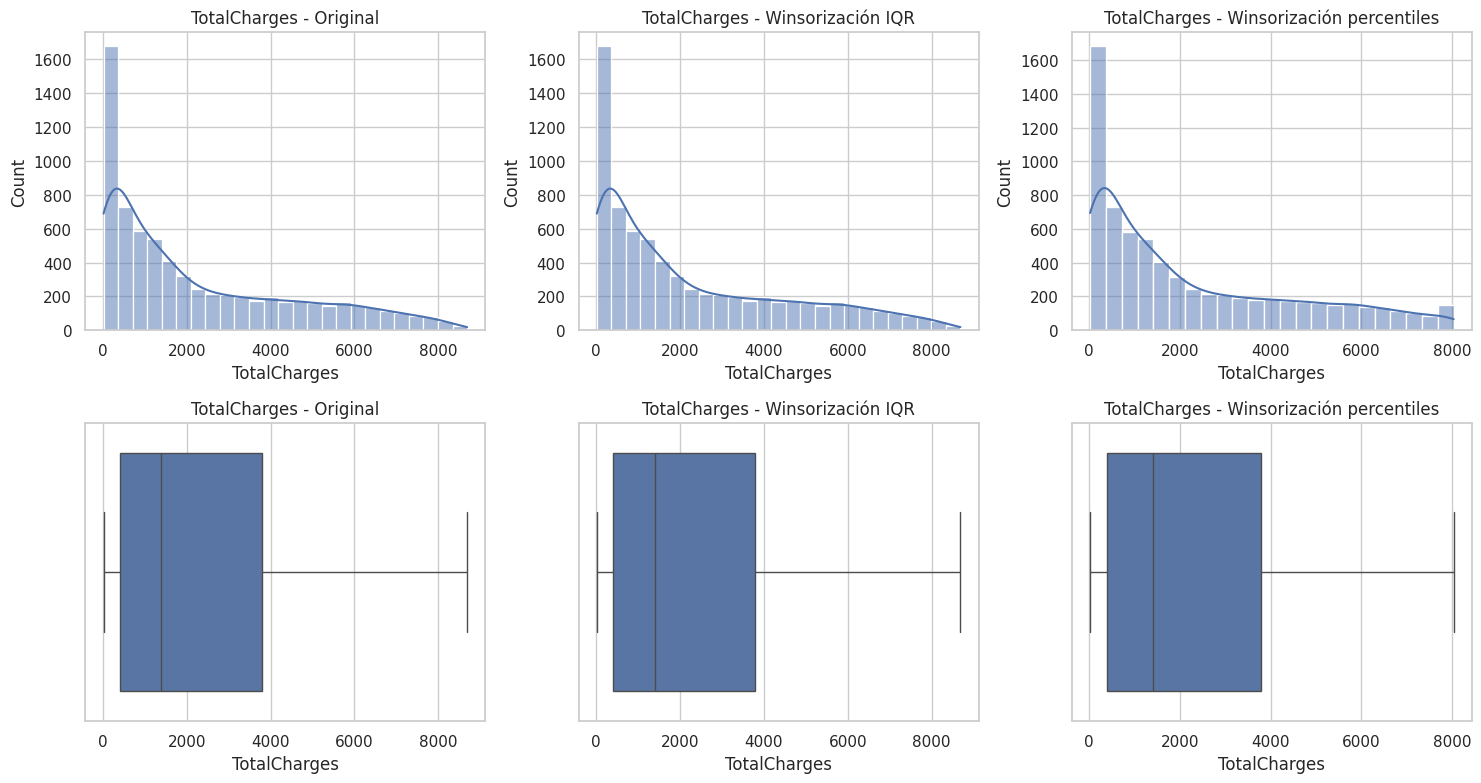

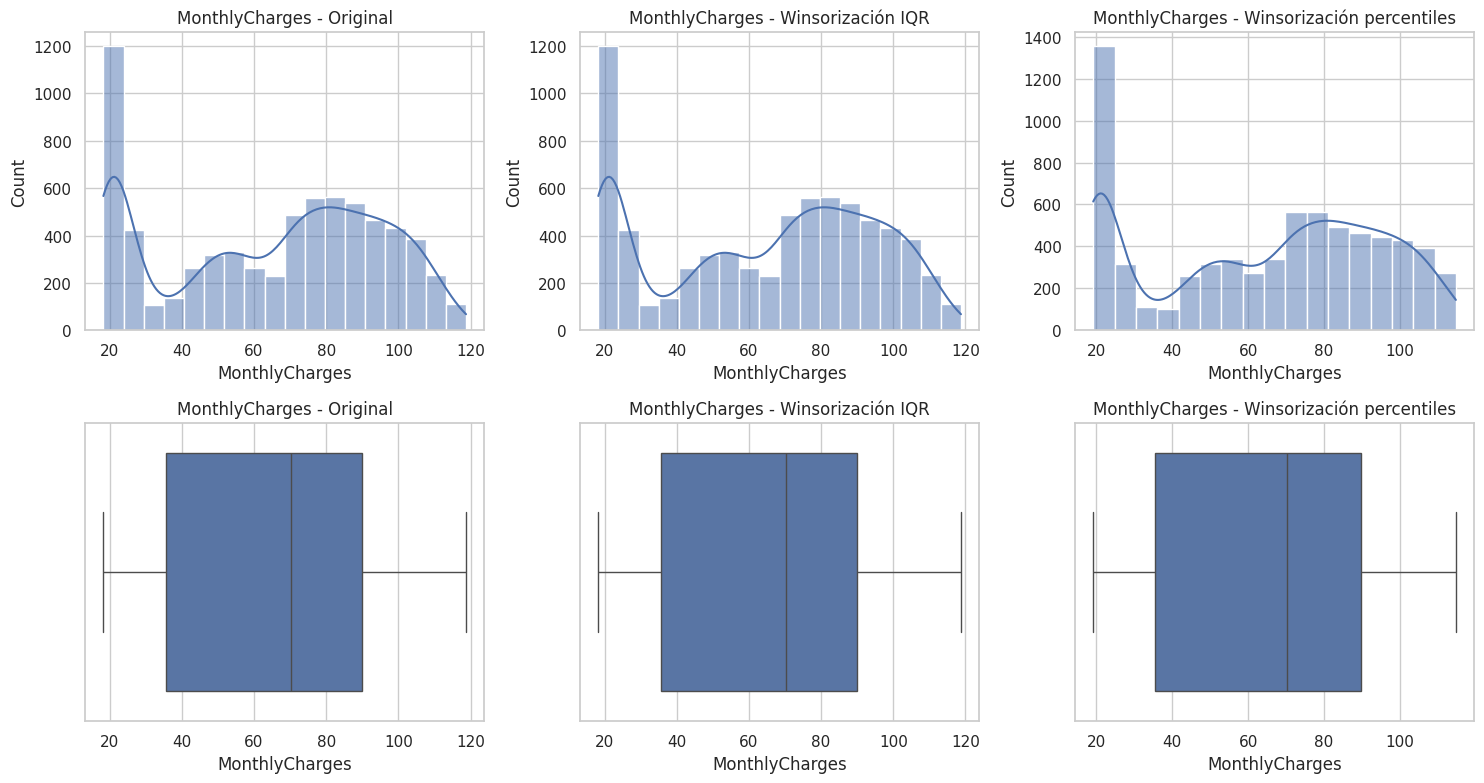

In [77]:
datasets = {"Original": df, "Winsorización IQR": df_iqr,
"Winsorización percentiles": df_percentiles}

for variable in variables_outliers:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for columna, (nombre, datos) in enumerate(datasets.items()):
        serie = datos[variable].dropna()

        # Histograma
        sns.histplot(serie, kde=True, ax=axes[0, columna])
        axes[0, columna].set_title(f"{variable} - {nombre}")
        axes[0, columna].set_xlabel(variable)

        # Diagrama de caja
        sns.boxplot(x=serie, ax=axes[1, columna])
        axes[1, columna].set_title(f"{variable} - {nombre}")
        axes[1, columna].set_xlabel(variable)

    plt.tight_layout()
    plt.show()

En la variable MonthlyCharges, los datos originales muestran una distribución con una alta concentración de valores cercanos a 20 y otras concentraciones a lo largo del rango de los cargos mensuales. Al aplicar la winsorización basada en el rango intercuartílico (IQR), los histogramas y diagramas de caja permanecieron prácticamente iguales, debido a que este criterio no identificó valores fuera de sus límites.

Por otro lado, la winsorización por percentiles modificó los extremos de la distribución al sustituir los valores inferiores al percentil 1 y superiores al percentil 99 por sus respectivos límites. Esto produjo una mayor concentración de observaciones cerca de dichos límites y redujo la extensión de los valores extremos, sin eliminar registros.

En la variable TotalCharges, los datos originales presentan una distribución sesgada a la derecha, con una concentración de registros en los valores bajos y una cola larga que se extiende hasta aproximadamente 8,685. La winsorización por IQR no produjo cambios visibles, mientras que la aplicación de percentiles acortó ligeramente el extremo superior de la distribución, limitando los valores máximos a 8,039.88.

La comparación muestra que el efecto del tratamiento depende del criterio utilizado: el IQR no modificó los datos de estas variables, mientras que la winsorización por percentiles limitó sus valores extremos.

###5.5 Comparar el desempeño del modelo

In [78]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
random_state=SEMILLA, stratify=y)
variables_numericas = X_train.select_dtypes(include="number").columns.tolist()
variables_categoricas = X_train.select_dtypes(exclude="number").columns.tolist()

def crear_modelo():
    transformador_numerico = Pipeline([("imputacion", SimpleImputer(strategy="mean")),
    ("escalado", StandardScaler())])
    transformador_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))])
    preprocesamiento = ColumnTransformer([
    ("numerico", transformador_numerico, variables_numericas),
    ("categorico", transformador_categorico, variables_categoricas)])

    return Pipeline([("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))])

X_train_iqr = X_train.copy()
X_test_iqr = X_test.copy()
X_train_pct = X_train.copy()
X_test_pct = X_test.copy()

for variable in variables_outliers:
    # IQR calculado solo con entrenamiento
    inferior, superior = limites_iqr(X_train[variable].dropna())
    X_train_iqr[variable] = X_train_iqr[variable].clip(inferior, superior)
    X_test_iqr[variable] = X_test_iqr[variable].clip(inferior, superior)

    # Percentiles calculados solo con entrenamiento
    inferior_pct = X_train[variable].quantile(0.01)
    superior_pct = X_train[variable].quantile(0.99)
    X_train_pct[variable] = X_train_pct[variable].clip(inferior_pct, superior_pct)
    X_test_pct[variable] = X_test_pct[variable].clip(inferior_pct, superior_pct)

estrategias = {"Original": (X_train, X_test),
"Winsorización IQR": (X_train_iqr, X_test_iqr),
"Winsorización percentiles": (X_train_pct, X_test_pct)}

resultados_modelo = []
for nombre, (Xtr, Xte) in estrategias.items():
    modelo = crear_modelo()
    modelo.fit(Xtr, y_train)
    predicciones = modelo.predict(Xte)

    resultados_modelo.append({"Tratamiento": nombre,
    "Accuracy": accuracy_score(y_test, predicciones),
    "Precision (Yes)": precision_score(y_test, predicciones,
    pos_label="Yes", zero_division=0), "Recall (Yes)": recall_score(
    y_test, predicciones, pos_label="Yes", zero_division=0),
    "F1-score (Yes)": f1_score(y_test, predicciones, pos_label="Yes",
    zero_division=0)})

tabla_modelo_outliers = pd.DataFrame(resultados_modelo).set_index("Tratamiento")
display(tabla_modelo_outliers.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
Tratamiento,,,,
Original,0.8055,0.6572,0.5588,0.6040
Winsorización IQR,0.8055,0.6572,0.5588,0.6040
Winsorización percentiles,0.8055,0.6562,0.5615,0.6052


Los resultados muestran que la winsorización por IQR no modificó el desempeño del modelo, mientras que la winsorización por percentiles produjo cambios muy pequeños.
- Original: obtuvo un accuracy de 80.55 % y un F1-score de 0.6040 para la clase Yes.
- Winsorización IQR: obtuvo exactamente las mismas métricas que los datos originales, lo cual coincide con que este criterio no modificó los valores de las variables analizadas.
- Winsorización por percentiles: mantuvo el accuracy en 80.55 %, pero el recall aumentó de 0.5588 a 0.5615 y el F1-score pasó de 0.6040 a 0.6052. La precisión disminuyó ligeramente de 0.6572 a 0.6562.

Estos cambios son mínimos, por lo que no se observa una mejora importante en el desempeño del modelo tras aplicar la winsorización por percentiles.

##6. Tratamiento de desbalance

###6.1 Calcular el desbalance de la variable objetivo

In [79]:
conteo_clases = df["Churn"].value_counts()
porcentaje_clases = df["Churn"].value_counts(normalize=True) * 100
tabla_balance = pd.DataFrame({"Cantidad": conteo_clases,
"Porcentaje (%)": porcentaje_clases})
display(tabla_balance.round(2))
clase_mayoritaria = conteo_clases.max()
clase_minoritaria = conteo_clases.min()
IR = clase_mayoritaria / clase_minoritaria
print(f"Clase mayoritaria: {conteo_clases.idxmax()}")
print(f"Clase minoritaria: {conteo_clases.idxmin()}")
print(f"Razón de desbalance (IR): {IR:.2f}")

if IR > 1.5:
    print("El dataset está desbalanceado (IR > 1.5).")
else:
    print("El dataset no supera el umbral de desbalance (IR <= 1.5).")

,Cantidad,Porcentaje (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


Clase mayoritaria: No
Clase minoritaria: Yes
Razón de desbalance (IR): 2.77
El dataset está desbalanceado (IR > 1.5).


Los resultados confirman que el dataset está desbalanceado, ya que la razón de desbalance es 2.77, superior al umbral de 1.5 establecido en la actividad.
La clase mayoritaria es No, con 5,174 observaciones (73.46 %), mientras que la clase minoritaria es Yes, con 1,869 observaciones (26.54 %). Esto significa que hay aproximadamente 2.77 registros de clientes que no cancelaron por cada registro de un cliente que sí canceló.
Este desequilibrio puede hacer que el modelo favorezca la clase mayoritaria y tenga dificultades para identificar a los clientes que cancelan. Por ello, compararemos distintas estrategias de balanceo, prestando especial atención al recall y al F1-score de la clase Yes.

###6.2 Preparar la comparación de estrategias

In [80]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y,
test_size=0.20, random_state=SEMILLA, stratify=y)
preprocesamiento = ColumnTransformer([("numerico", Pipeline([
("imputacion", SimpleImputer(strategy="mean")), ("escalado", StandardScaler())]),
X_train.select_dtypes(include="number").columns.tolist()), ("categorico",
Pipeline([("imputacion", SimpleImputer(strategy="most_frequent")),
("codificacion", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
X_train.select_dtypes(exclude="number").columns.tolist())])
X_train_proc = preprocesamiento.fit_transform(X_train)
X_test_proc = preprocesamiento.transform(X_test)
nombres_columnas = preprocesamiento.get_feature_names_out()
X_train_proc = pd.DataFrame(X_train_proc, columns=nombres_columnas, index=X_train.index)
X_test_proc = pd.DataFrame(X_test_proc, columns=nombres_columnas, index=X_test.index)

# Estrategia 1: sobremuestreo aleatorio
sobremuestreo = RandomOverSampler(random_state=SEMILLA)
X_train_over, y_train_over = sobremuestreo.fit_resample(X_train_proc, y_train)

# Estrategia 2: submuestreo aleatorio
submuestreo = RandomUnderSampler(random_state=SEMILLA)
X_train_under, y_train_under = submuestreo.fit_resample(X_train_proc, y_train)

# Estrategia 3: SMOTE
smote = SMOTE(random_state=SEMILLA)
X_train_smote, y_train_smote = smote.fit_resample(X_train_proc, y_train)

# Resumir las cantidades después del balanceo
resumen_balanceo = pd.DataFrame({"Estrategia": ["Sobremuestreo aleatorio",
"Submuestreo aleatorio", "SMOTE"], "No": [(y_train_over == "No").sum(),
(y_train_under == "No").sum(), (y_train_smote == "No").sum()], "Yes":
[(y_train_over == "Yes").sum(), (y_train_under == "Yes").sum(),
(y_train_smote == "Yes").sum()], "Total": [len(y_train_over),
len(y_train_under), len(y_train_smote)]})

display(resumen_balanceo)

,Estrategia,No,Yes,Total
0,Sobremuestreo aleatorio,4139,4139,8278
1,Submuestreo aleatorio,1495,1495,2990
2,SMOTE,4139,4139,8278


Los resultados confirman que las tres estrategias equilibraron las clases del conjunto de entrenamiento, aunque lo hicieron de maneras diferentes:
- Sobremuestreo aleatorio: aumentó la clase minoritaria Yes de 1,495 a 4,139 registros, duplicando observaciones existentes.
- Submuestreo aleatorio: redujo la clase mayoritaria No de 4,139 a 1,495 registros, por lo que se utilizaron menos datos para entrenar.
- SMOTE: generó ejemplos sintéticos de la clase Yes hasta igualar los 4,139 registros de la clase No.
En los tres casos, las clases quedaron equilibradas. La diferencia es que el sobremuestreo replica registros, el submuestreo descarta registros mayoritarios y SMOTE crea ejemplos sintéticos.

###6.3 Entrenar y evaluar los modelos

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

estrategias_balanceo = {"Sobremuestreo aleatorio": (X_train_over, y_train_over),
"Submuestreo aleatorio": (X_train_under, y_train_under), "SMOTE": (X_train_smote, y_train_smote)}
resultados_balanceo = []
for nombre, (Xtr, ytr) in estrategias_balanceo.items():
    modelo = LogisticRegression(max_iter=1000, random_state=SEMILLA)
    modelo.fit(Xtr, ytr)
    predicciones = modelo.predict(X_test_proc)
    resultados_balanceo.append({"Estrategia": nombre,
    "Accuracy": accuracy_score(y_test, predicciones),"Precision (Yes)":
    precision_score(y_test, predicciones, pos_label="Yes", zero_division=0),
    "Recall (Yes)": recall_score(y_test, predicciones, pos_label="Yes",
    zero_division=0), "F1-score (Yes)": f1_score(y_test, predicciones,
    pos_label="Yes", zero_division=0)})

tabla_resultados_balanceo = (pd.DataFrame(resultados_balanceo).set_index("Estrategia"))
display(tabla_resultados_balanceo.round(4))

,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
Estrategia,,,,
Sobremuestreo aleatorio,0.7353,0.5009,0.7861,0.6119
Submuestreo aleatorio,0.7438,0.5113,0.7861,0.6196
SMOTE,0.7381,0.5042,0.7941,0.6168


Sobremuestreo aleatorio: obtuvo un accuracy de 73.53 %, un recall de 0.7861 y un F1-score de 0.6119. Detectó una proporción alta de las cancelaciones, aunque su precisión fue de 0.5009.

Submuestreo aleatorio: alcanzó el mayor accuracy (74.38 %) y el mayor F1-score (0.6196). Su recall fue de 0.7861, igual al del sobremuestreo, y obtuvo la mayor precisión de las tres estrategias (0.5113).

SMOTE: consiguió el mayor recall (0.7941), lo que significa que identificó una proporción ligeramente mayor de las cancelaciones reales. Sin embargo, su accuracy fue de 73.81 % y su F1-score de 0.6168, ambos ligeramente inferiores a los del submuestreo.